In [ ]:
# Data Directory Configuration
import os
ROOT = os.environ.get("SEEM3650_DATA_DIR", "./data")
print(f"Using SEEM3650 data root: {ROOT}")


In [4]:
import pandas as pd

ROOT    = './data'
RAW_DIR = f'{ROOT}/RAW_DATA_METER/DATA_FILE'
META    = f'{ROOT}/parkingspaces.csv'

df = pd.read_csv(f'{RAW_DIR}/20260117-1029-occupancystatus.csv', encoding='utf-8-sig')
print('Snapshot shape:', df.shape)
print('Columns:', df.columns.tolist())
print(df.head())
print('Meter status:', df['ParkingMeterStatus'].value_counts().to_dict())
print('Occupancy:', df['OccupancyStatus'].value_counts().to_dict())

meta = pd.read_csv(META, encoding='utf-8-sig', skiprows=2)
print('Metadata shape:', meta.shape)
print('Top districts:', meta['District'].value_counts().head().to_dict())

Snapshot shape: (20407, 4)
Columns: ['ParkingSpaceId', 'ParkingMeterStatus', 'OccupancyStatus', 'OccupancyDateChanged']
  ParkingSpaceId ParkingMeterStatus OccupancyStatus    OccupancyDateChanged
0         10006A                  N               O  01/17/2026 10:13:42 AM
1         10006B                  N               V  01/17/2026 10:28:15 AM
2         10007A                  N               O  01/16/2026 01:14:33 PM
3         10007B                  N               O  01/17/2026 08:36:44 AM
4         10008A                  N               O  01/17/2026 10:00:11 AM
Meter status: {'N': 20145, 'NU': 262}
Occupancy: {'O': 15515, 'V': 4892}
Metadata shape: (20559, 24)
Top districts: {'KOWLOON CITY': 2639, 'YAU TSIM MONG': 1993, 'SAI KUNG': 1983, 'SHA TIN': 1702, 'TAI PO': 1633}


In [5]:
import re, glob
import numpy as np

DATE_RE = re.compile(r'(\d{8})-')

def load_snapshot(path):
    fname = path.split('/')[-1]
    date = pd.to_datetime(DATE_RE.search(fname).group(1), format='%Y%m%d')
    df = pd.read_csv(path, encoding='utf-8-sig')
    df = df[df['ParkingMeterStatus'] == 'N'].copy()
    df['Occupied'] = (df['OccupancyStatus'] == 'O').astype(int)
    df['Date'] = date
    df['ParkingSpaceId'] = df['ParkingSpaceId'].astype(str).str.strip()
    return df[['ParkingSpaceId', 'Date', 'Occupied']]

test = load_snapshot(f'{RAW_DIR}/20260117-1029-occupancystatus.csv')
print(test.head())
print('Rows:', test.shape[0], '| Mean occupied:', test['Occupied'].mean().round(4))

  ParkingSpaceId       Date  Occupied
0         10006A 2026-01-17         1
1         10006B 2026-01-17         0
2         10007A 2026-01-17         1
3         10007B 2026-01-17         1
4         10008A 2026-01-17         1
Rows: 20145 | Mean occupied: 0.7617


In [6]:
files = sorted(glob.glob(f'{RAW_DIR}/*occupancystatus.csv'))
print(f'Files found: {len(files)}')

all_snaps = pd.concat([load_snapshot(f) for f in files], ignore_index=True)
print(f'Total rows: {len(all_snaps):,}')
print(f'Date range: {all_snaps["Date"].min().date()} to {all_snaps["Date"].max().date()}')
print(f'Unique meter IDs: {all_snaps["ParkingSpaceId"].nunique():,}')

Files found: 365
Total rows: 7,323,750
Date range: 2025-04-01 to 2026-03-31
Unique meter IDs: 20,568


In [7]:
meta = pd.read_csv(META, encoding='utf-8-sig', skiprows=2)
meta['ParkingSpaceId'] = meta['ParkingSpaceId'].astype(str).str.strip()

merged = all_snaps.merge(meta[['ParkingSpaceId', 'District']], on='ParkingSpaceId', how='inner')
print(f'Merged rows: {len(merged):,}')

merged = merged[merged['District'] != 'INTERNAL TEST']

panel = (merged.groupby(['Date', 'District'])
                .agg(NumSpaces=('Occupied', 'size'),
                     NumOccupied=('Occupied', 'sum'))
                .reset_index())
panel['DailyOccupancy'] = panel['NumOccupied'] / panel['NumSpaces']

print(f'Panel rows: {len(panel)}  (expected 18 * 365 = {18*365})')
print(panel.head())

Merged rows: 7,314,654
Panel rows: 6570  (expected 18 * 365 = 6570)
        Date           District  NumSpaces  NumOccupied  DailyOccupancy
0 2025-04-01  CENTRAL & WESTERN        589          511        0.867572
1 2025-04-01            EASTERN        584          545        0.933219
2 2025-04-01            ISLANDS        171          112        0.654971
3 2025-04-01       KOWLOON CITY       2550         2352        0.922353
4 2025-04-01         KWAI TSING        581          496        0.853701


In [8]:
holidays_csv = """Date,HolidayName
2025-04-04,Ching Ming Festival
2025-04-18,Good Friday
2025-04-19,Day after Good Friday
2025-04-21,Easter Monday
2025-05-01,Labour Day
2025-05-05,Buddha's Birthday
2025-05-31,Tuen Ng Festival
2025-07-01,HKSAR Establishment Day
2025-10-01,National Day
2025-10-07,Day after Mid-Autumn Festival
2025-10-29,Chung Yeung Festival
2025-12-25,Christmas Day
2025-12-26,First weekday after Christmas
2026-01-01,New Year's Day
2026-02-17,Lunar New Year's Day
2026-02-18,Second day of Lunar New Year
2026-02-19,Third day of Lunar New Year
"""

with open(f'{ROOT}/holidays_full_year.csv', 'w') as f:
    f.write(holidays_csv)
print('Wrote holidays_full_year.csv')

Wrote holidays_full_year.csv


In [9]:
RAIN_FILE = f'{ROOT}/RAW_DATA_RAIN/20260416-1020-daily_HKO_RF_ALL.csv'

wx = pd.read_csv(RAIN_FILE, encoding='utf-8-sig', usecols=[0, 1, 2, 3])
wx.columns = ['Year', 'Month', 'Day', 'Value']

wx = wx[pd.to_numeric(wx['Year'], errors='coerce').notna()].copy()
wx[['Year', 'Month', 'Day']] = wx[['Year', 'Month', 'Day']].astype(int)

# remap "Trace" entries to a small number
wx['Precipitation_mm'] = wx['Value'].replace('Trace', 0.025).astype(float)

wx['Date'] = pd.to_datetime(wx[['Year', 'Month', 'Day']])
wx = wx[['Date', 'Precipitation_mm']].sort_values('Date').reset_index(drop=True)

print(f'Rainfall rows: {len(wx)}')
print(f'Date range: {wx["Date"].min().date()} to {wx["Date"].max().date()}')
print(f'Annual total: {wx["Precipitation_mm"].sum():.1f} mm')
print('Monthly totals:')
print(wx.groupby(wx['Date'].dt.to_period('M'))['Precipitation_mm'].sum().round(1).to_string())

Rainfall rows: 365
Date range: 2025-04-01 to 2026-03-31
Annual total: 2690.7 mm
Monthly totals:
Date
2025-04     57.2
2025-05     81.8
2025-06    237.4
2025-07    601.7
2025-08    939.2
2025-09    528.8
2025-10     31.4
2025-11      7.1
2025-12      6.6
2026-01      3.3
2026-02     41.7
2026-03    154.6
Freq: M


In [10]:
panel['Date'] = pd.to_datetime(panel['Date'])
panel = panel.merge(wx, on='Date', how='left')
panel['Precipitation_mm'] = panel['Precipitation_mm'].fillna(0.0)
panel['RainyDay']  = (panel['Precipitation_mm'] >= 1.0).astype(int)
panel['HeavyRain'] = (panel['Precipitation_mm'] >= 10.0).astype(int)

dow_map = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}
panel['DayOfWeek'] = panel['Date'].dt.dayofweek.map(dow_map)

hol = pd.read_csv(f'{ROOT}/holidays_full_year.csv')
hol['Date'] = pd.to_datetime(hol['Date'])
panel['Holiday']     = panel['Date'].isin(set(hol['Date'])).astype(int)
panel['IsCNYPeriod'] = panel['Date'].between('2026-02-14', '2026-02-22').astype(int)

PRICE_CHANGE_DATE = pd.Timestamp('2025-09-28')
panel['PostPriceChange']    = (panel['Date'] >= PRICE_CHANGE_DATE).astype(int)
panel['Price_HKD_per_hour'] = np.where(panel['PostPriceChange'] == 1, 16.0, 8.0)

panel = panel.sort_values(['Date', 'District']).reset_index(drop=True)
panel.to_csv(f'{ROOT}/panel_daily.csv', index=False)

print(f'Panel shape: {panel.shape}')
print(f'Columns ({len(panel.columns)}):', list(panel.columns))
print()
print('Pre vs post price change:')
print(panel.groupby('PostPriceChange')['DailyOccupancy'].agg(['mean', 'std', 'count']).round(4).to_string())
print()
print('Mean occupancy by district:')
print(panel.groupby('District')['DailyOccupancy'].mean().sort_values(ascending=False).round(4).to_string())

Panel shape: (6570, 13)
Columns (13): ['Date', 'District', 'NumSpaces', 'NumOccupied', 'DailyOccupancy', 'Precipitation_mm', 'RainyDay', 'HeavyRain', 'DayOfWeek', 'Holiday', 'IsCNYPeriod', 'PostPriceChange', 'Price_HKD_per_hour']

Pre vs post price change:
                   mean    std  count
PostPriceChange                      
0                0.7731  0.134   3240
1                0.7331  0.139   3330

Mean occupancy by district:
District
YAU TSIM MONG        0.9434
SHAM SHUI PO         0.8972
WONG TAI SIN         0.8968
WAN CHAI             0.8893
EASTERN              0.8705
KOWLOON CITY         0.8495
CENTRAL & WESTERN    0.8471
KWUN TONG            0.8047
KWAI TSING           0.7870
TSUEN WAN            0.7303
YUEN LONG            0.7131
SHA TIN              0.6810
NORTH                0.6716
TUEN MUN             0.6631
SOUTHERN             0.6413
ISLANDS              0.6147
TAI PO               0.5820
SAI KUNG             0.4686


In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIGDIR = f'{ROOT}/outputs/figures'
TABDIR = f'{ROOT}/outputs/tables'
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(TABDIR, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

TARGET = 0.90
PRICE_CHANGE = pd.Timestamp('2025-09-28')

cluster_order = (panel.groupby('District')['DailyOccupancy']
                       .mean().sort_values(ascending=False).index.tolist())
print('Cluster order:', cluster_order)

Cluster order: ['YAU TSIM MONG', 'SHAM SHUI PO', 'WONG TAI SIN', 'WAN CHAI', 'EASTERN', 'KOWLOON CITY', 'CENTRAL & WESTERN', 'KWUN TONG', 'KWAI TSING', 'TSUEN WAN', 'YUEN LONG', 'SHA TIN', 'NORTH', 'TUEN MUN', 'SOUTHERN', 'ISLANDS', 'TAI PO', 'SAI KUNG']


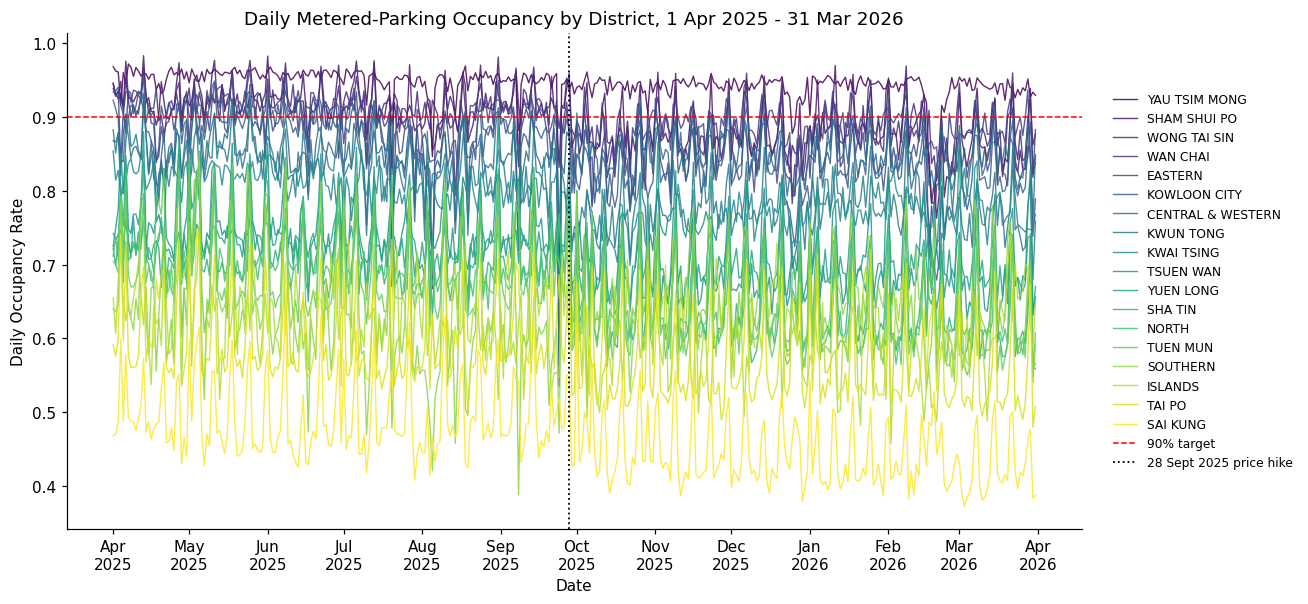

In [12]:
fig, ax = plt.subplots(figsize=(12, 5.6))
cmap = plt.get_cmap('viridis')

for i, c in enumerate(cluster_order):
    sub = panel[panel['District'] == c].sort_values('Date')
    ax.plot(sub['Date'], sub['DailyOccupancy'],
            color=cmap(i / max(len(cluster_order)-1, 1)),
            lw=0.9, alpha=0.85, label=c)

ax.axhline(TARGET, color='red', ls='--', lw=1.0, label='90% target')
ax.axvline(PRICE_CHANGE, color='black', ls=':', lw=1.2, label='28 Sept 2025 price hike')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Occupancy Rate')
ax.set_title('Daily Metered-Parking Occupancy by District, 1 Apr 2025 - 31 Mar 2026')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig01_timeseries_all_clusters.png', bbox_inches='tight')
plt.show()

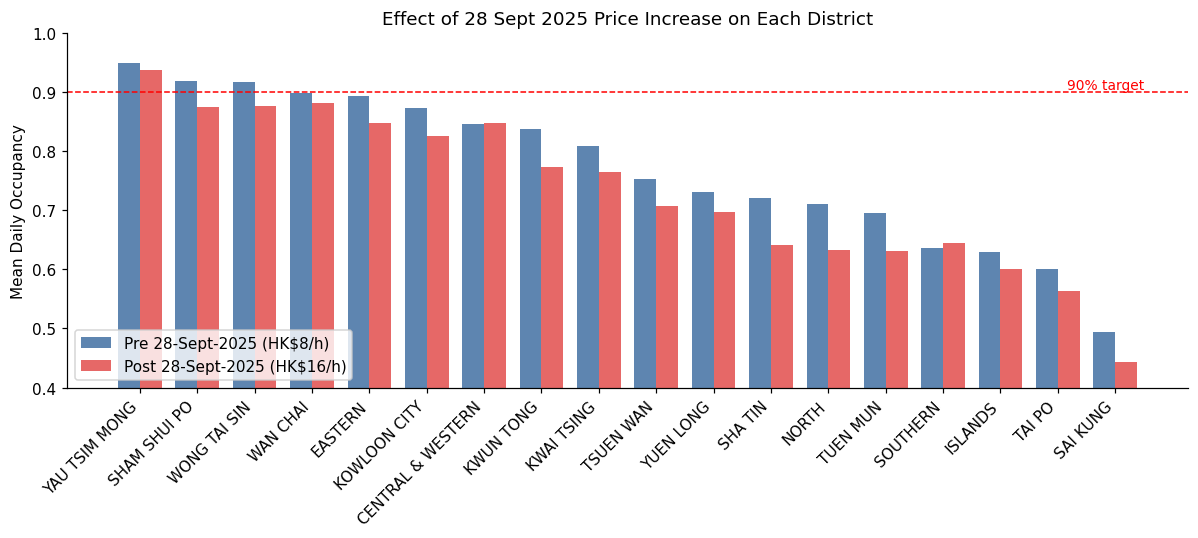

         District  PreMeanOcc  PostMeanOcc  Delta_pp
    YAU TSIM MONG       0.949        0.938    -1.185
     SHAM SHUI PO       0.919        0.876    -4.346
     WONG TAI SIN       0.917        0.877    -3.915
         WAN CHAI       0.898        0.881    -1.696
          EASTERN       0.894        0.848    -4.583
     KOWLOON CITY       0.874        0.826    -4.797
CENTRAL & WESTERN       0.846        0.849     0.278
        KWUN TONG       0.837        0.773    -6.435
       KWAI TSING       0.809        0.765    -4.363
        TSUEN WAN       0.754        0.707    -4.647
        YUEN LONG       0.730        0.696    -3.385
          SHA TIN       0.722        0.642    -8.010
            NORTH       0.711        0.634    -7.695
         TUEN MUN       0.696        0.632    -6.409
         SOUTHERN       0.637        0.645     0.843
          ISLANDS       0.630        0.600    -2.957
           TAI PO       0.601        0.564    -3.680
         SAI KUNG       0.494        0.444    

In [13]:
# ============
# Figure 1
# ============
pre_means, post_means = [], []
for c in cluster_order:
    pre_means.append(panel.query("District == @c and PostPriceChange == 0")['DailyOccupancy'].mean())
    post_means.append(panel.query("District == @c and PostPriceChange == 1")['DailyOccupancy'].mean())

fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(cluster_order))
width = 0.38

ax.bar(positions - width/2, pre_means, width, color='#4c78a8', label='Pre 28-Sept-2025 (HK$8/h)', alpha=0.9)
ax.bar(positions + width/2, post_means, width, color='#e45756', label='Post 28-Sept-2025 (HK$16/h)', alpha=0.9)
ax.axhline(TARGET, color='red', ls='--', lw=1.0)
ax.text(len(cluster_order)-0.5, TARGET+0.005, '90% target', color='red', fontsize=9, ha='right')
ax.set_xticks(positions)
ax.set_xticklabels(cluster_order, rotation=45, ha='right')
ax.set_ylabel('Mean Daily Occupancy')
ax.set_title('Effect of 28 Sept 2025 Price Increase on Each District')
ax.set_ylim(0.4, 1.0)
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig02_pre_vs_post_price.png', bbox_inches='tight')
plt.show()

shifts = pd.DataFrame({
    'District': cluster_order,
    'PreMeanOcc': pre_means,
    'PostMeanOcc': post_means,
})
shifts['Delta_pp'] = (np.array(post_means) - np.array(pre_means)) * 100
shifts.round(4).to_csv(f'{TABDIR}/regime_shifts.csv', index=False)
print(shifts.round(3).to_string(index=False))

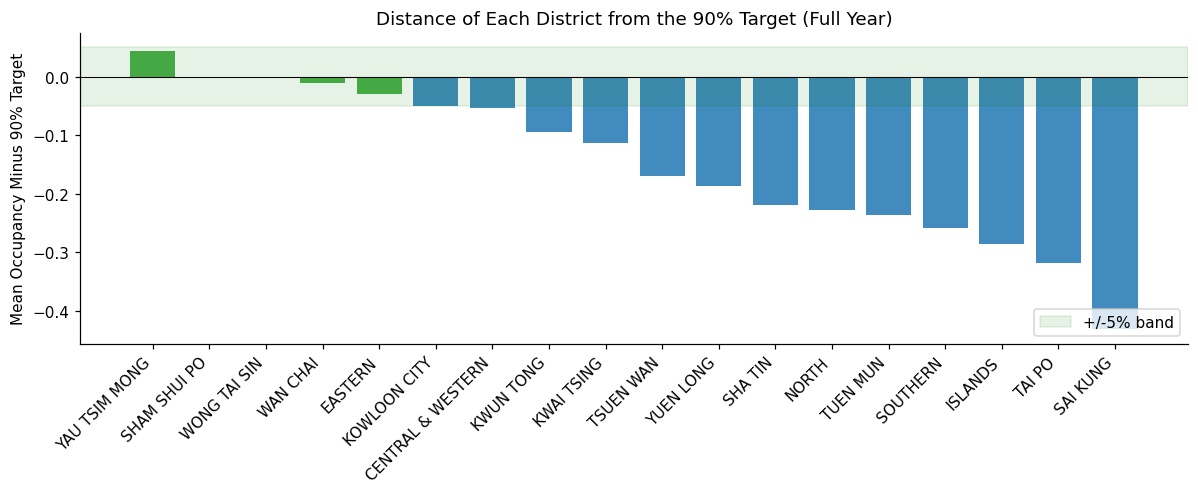

In [14]:
# ============
# Figure 2
# ============
gap = (panel.groupby('District')['DailyOccupancy'].mean().sub(TARGET).reindex(cluster_order))

fig, ax = plt.subplots(figsize=(11, 4.6))
colors = ['#d62728' if v > 0.05 else '#2ca02c' if abs(v) <= 0.05 else '#1f77b4' for v in gap.values]
ax.bar(gap.index, gap.values, color=colors, alpha=0.85)
ax.axhline(0, color='black', lw=0.7)
ax.axhspan(-0.05, 0.05, color='green', alpha=0.10, label='+/-5% band')
ax.set_ylabel('Mean Occupancy Minus 90% Target')
ax.set_title('Distance of Each District from the 90% Target (Full Year)')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig06_distance_from_target.png', bbox_inches='tight')
plt.show()

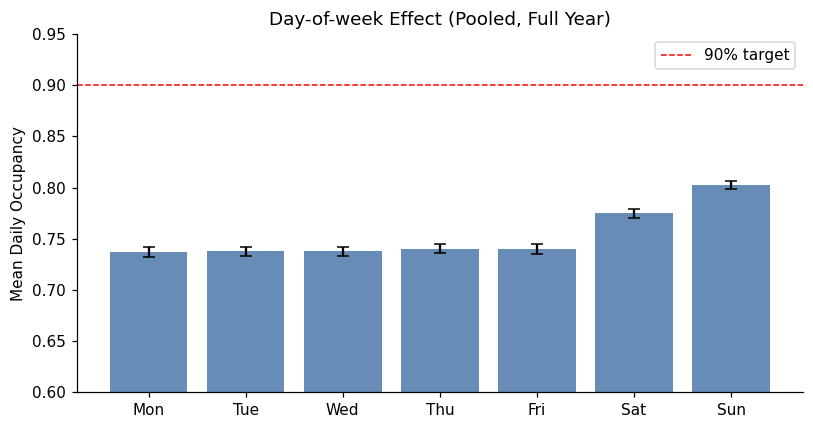

In [15]:
dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_means = (panel.groupby('DayOfWeek')['DailyOccupancy'].agg(['mean', 'std', 'count']).reindex(dow_order))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(dow_means.index, dow_means['mean'],
       yerr=dow_means['std'] / np.sqrt(dow_means['count']),
       color='#4c78a8', alpha=0.85, capsize=4)
ax.axhline(TARGET, color='red', ls='--', lw=1.0, label='90% target')
ax.set_ylabel('Mean Daily Occupancy')
ax.set_title('Day-of-week Effect (Pooled, Full Year)')
ax.set_ylim(0.6, 0.95)
ax.legend()
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig04_dayofweek_effect.png', bbox_inches='tight')
plt.show()

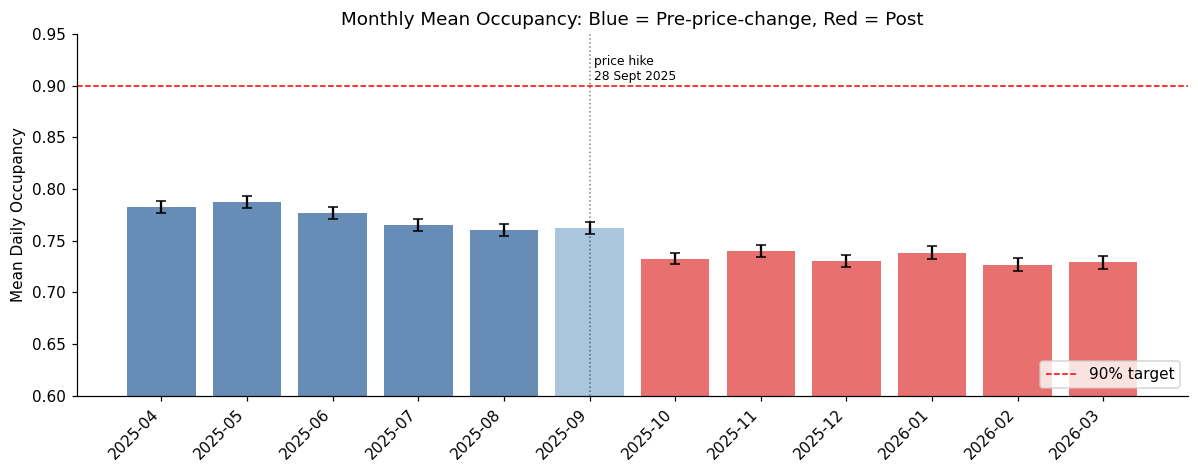

In [16]:
panel['YearMonth'] = panel['Date'].dt.to_period('M').astype(str)
month_order = sorted(panel['YearMonth'].unique())
month_means = (panel.groupby('YearMonth')['DailyOccupancy'].agg(['mean', 'std', 'count']).reindex(month_order))

def regime_color(month_str):
    if month_str < '2025-09':
        return '#4c78a8'
    if month_str == '2025-09':
        return '#9bbcd8'
    return '#e45756'

fig, ax = plt.subplots(figsize=(11, 4.4))
xpos = np.arange(len(month_means))
ax.bar(xpos, month_means['mean'],
       yerr=month_means['std'] / np.sqrt(month_means['count']),
       color=[regime_color(m) for m in month_means.index],
       alpha=0.85, capsize=3)
ax.axhline(TARGET, color='red', ls='--', lw=1.0, label='90% target')
ax.axvline(5, color='black', ls=':', lw=1.0, alpha=0.5)
ax.text(5.05, 0.93, 'price hike\n28 Sept 2025', fontsize=8, va='top')
ax.set_xticks(xpos)
ax.set_xticklabels(month_means.index, rotation=45, ha='right')
ax.set_ylabel('Mean Daily Occupancy')
ax.set_title('Monthly Mean Occupancy: Blue = Pre-price-change, Red = Post')
ax.set_ylim(0.6, 0.95)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig05_monthly_seasonality.png', bbox_inches='tight')
plt.show()

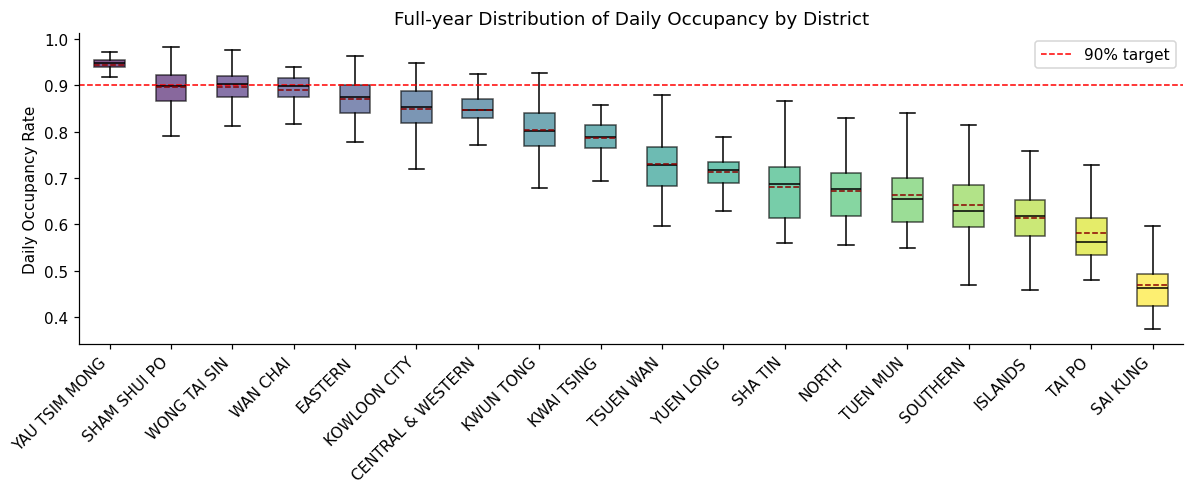

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.6))
data_box = [panel[panel['District'] == c]['DailyOccupancy'].values for c in cluster_order]
bp = ax.boxplot(data_box, tick_labels=cluster_order, patch_artist=True,
                showmeans=True, meanline=True, showfliers=False,
                medianprops=dict(color='black'),
                meanprops=dict(color='darkred', ls='--'))
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(cmap(i / max(len(cluster_order)-1, 1)))
    patch.set_alpha(0.65)
ax.axhline(TARGET, color='red', ls='--', lw=1.0, label='90% target')
ax.set_ylabel('Daily Occupancy Rate')
ax.set_title('Full-year Distribution of Daily Occupancy by District')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig03_boxplot_clusters.png', bbox_inches='tight')
plt.show()

In [18]:
!pip install -q statsmodels

In [19]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import json
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import statsmodels.api as sm
import joblib

np.random.seed(20260501)

RESDIR = f'{ROOT}/outputs/results'
os.makedirs(RESDIR, exist_ok=True)

FEATURES_NUM = ['Precipitation_mm', 'RainyDay', 'HeavyRain', 'Holiday', 'IsCNYPeriod', 'PostPriceChange']
FEATURES_CAT = ['District', 'DayOfWeek']
TARGET_COL = 'DailyOccupancy'

X = panel[FEATURES_NUM + FEATURES_CAT].copy()
y = panel[TARGET_COL].values

print(f'Rows: {len(panel):,} | districts: {panel["District"].nunique()} | days: {panel["Date"].nunique()}')
print(f'Target: mean = {y.mean():.4f}, sd = {y.std():.4f}')
print(f'Features ({len(FEATURES_NUM) + len(FEATURES_CAT)} total):')
print(f'  Numerical:   {FEATURES_NUM}')
print(f'  Categorical: {FEATURES_CAT}')

Rows: 6,570 | districts: 18 | days: 365
Target: mean = 0.7529, sd = 0.1380
Features (8 total):
  Numerical:   ['Precipitation_mm', 'RainyDay', 'HeavyRain', 'Holiday', 'IsCNYPeriod', 'PostPriceChange']
  Categorical: ['District', 'DayOfWeek']


In [20]:
# Time-series CV split on unique dates
unique_dates = np.array(sorted(panel['Date'].unique()))
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

cv_iter = []
for tr_d, te_d in tscv.split(unique_dates):
    train_dates = set(unique_dates[tr_d])
    test_dates = set(unique_dates[te_d])
    tr_idx = panel.index[panel['Date'].isin(train_dates)].to_numpy()
    te_idx = panel.index[panel['Date'].isin(test_dates)].to_numpy()
    cv_iter.append((tr_idx, te_idx))

print(f'TimeSeriesSplit: {n_splits} chronological folds')
for k, (tr, te) in enumerate(cv_iter, 1):
    tr_dates = sorted(panel.loc[tr, 'Date'].unique())
    te_dates = sorted(panel.loc[te, 'Date'].unique())
    print(f'  Fold {k}: train {len(tr_dates):3d} days '
          f'({pd.Timestamp(tr_dates[0]).date()} -> {pd.Timestamp(tr_dates[-1]).date()}) '
          f'| test {len(te_dates):3d} days '
          f'({pd.Timestamp(te_dates[0]).date()} -> {pd.Timestamp(te_dates[-1]).date()})')

TimeSeriesSplit: 5 chronological folds
  Fold 1: train  65 days (2025-04-01 -> 2025-06-04) | test  60 days (2025-06-05 -> 2025-08-03)
  Fold 2: train 125 days (2025-04-01 -> 2025-08-03) | test  60 days (2025-08-04 -> 2025-10-02)
  Fold 3: train 185 days (2025-04-01 -> 2025-10-02) | test  60 days (2025-10-03 -> 2025-12-01)
  Fold 4: train 245 days (2025-04-01 -> 2025-12-01) | test  60 days (2025-12-02 -> 2026-01-30)
  Fold 5: train 305 days (2025-04-01 -> 2026-01-30) | test  60 days (2026-01-31 -> 2026-03-31)


In [22]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), FEATURES_NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), FEATURES_CAT),
    ])

models = {
    'Linear (OLS)':      Pipeline([('prep', make_preprocessor()), ('est', LinearRegression())]),
    'Ridge (l2)':        Pipeline([('prep', make_preprocessor()), ('est', Ridge(random_state=0))]),
    'Lasso (l1)':        Pipeline([('prep', make_preprocessor()), ('est', Lasso(random_state=0, max_iter=20000))]),
    'Random Forest':     Pipeline([('prep', make_preprocessor()), ('est', RandomForestRegressor(random_state=0, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('prep', make_preprocessor()), ('est', GradientBoostingRegressor(random_state=0))]),
}

grids = {
    'Linear (OLS)':      {},
    'Ridge (l2)':        {'est__alpha': [0.01, 0.1, 1.0, 10.0]},
    'Lasso (l1)':        {'est__alpha': [0.0001, 0.001, 0.01, 0.05]},
    'Random Forest':     {'est__n_estimators': [200, 400], 'est__max_depth': [None, 6, 10], 'est__min_samples_leaf': [1, 3]},
    'Gradient Boosting': {'est__n_estimators': [200, 400], 'est__learning_rate': [0.05, 0.1], 'est__max_depth': [2, 3, 4]},
}

print('Grid search (about 2-3 min)...\n')

rows, fitted = [], {}
for name, pipe in models.items():
    gs = GridSearchCV(pipe, grids[name], cv=cv_iter, scoring='neg_mean_squared_error', n_jobs=-1, refit=True)
    gs.fit(X, y)

    best_pipe = gs.best_estimator_
    per_fold = []
    for tr, te in cv_iter:
        best_pipe.fit(X.iloc[tr], y[tr])
        yhat = best_pipe.predict(X.iloc[te])
        per_fold.append({
            'rmse': np.sqrt(mean_squared_error(y[te], yhat)),
            'mae':  mean_absolute_error(y[te], yhat),
            'r2':   r2_score(y[te], yhat),
        })
    rmse = np.mean([r['rmse'] for r in per_fold])
    rmse_sd = np.std([r['rmse'] for r in per_fold])
    mae = np.mean([r['mae'] for r in per_fold])
    r2 = np.mean([r['r2'] for r in per_fold])

    rows.append({
        'Model': name,
        'BestParams': json.dumps(gs.best_params_),
        'RMSE_mean': round(rmse, 5),
        'RMSE_sd': round(rmse_sd, 5),
        'MAE_mean': round(mae, 5),
        'R2_mean': round(r2, 4),
    })

    best_pipe.fit(X, y)
    fitted[name] = best_pipe

    print(f'{name}: RMSE = {rmse:.5f} (sd {rmse_sd:.5f}), MAE = {mae:.5f}, R2 = {r2:.4f}')
    print(f'   best params: {gs.best_params_}\n')

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(f'{RESDIR}/model_metrics.csv', index=False)
print('Final metrics:')
print(metrics_df.to_string(index=False))

Grid search (about 2-3 min)...

Linear (OLS): RMSE = 0.04175 (sd 0.00262), MAE = 0.03157, R2 = 0.9065
   best params: {}

Ridge (l2): RMSE = 0.04175 (sd 0.00261), MAE = 0.03157, R2 = 0.9064
   best params: {'est__alpha': 0.01}

Lasso (l1): RMSE = 0.04213 (sd 0.00252), MAE = 0.03213, R2 = 0.9049
   best params: {'est__alpha': 0.0001}

Random Forest: RMSE = 0.03440 (sd 0.00300), MAE = 0.02414, R2 = 0.9361
   best params: {'est__max_depth': None, 'est__min_samples_leaf': 1, 'est__n_estimators': 200}

Gradient Boosting: RMSE = 0.03459 (sd 0.00329), MAE = 0.02457, R2 = 0.9352
   best params: {'est__learning_rate': 0.1, 'est__max_depth': 4, 'est__n_estimators': 400}

Final metrics:
            Model                                                                     BestParams  RMSE_mean  RMSE_sd  MAE_mean  R2_mean
     Linear (OLS)                                                                             {}    0.04175  0.00262   0.03157   0.9065
       Ridge (l2)                          

In [23]:
EPS = 1e-3

reg_rows = []
for c in panel['District'].unique():
    sub = panel[panel['District'] == c].copy()
    sub['log_occ'] = np.log(sub['DailyOccupancy'] + EPS)

    formula = ('log_occ ~ PostPriceChange + Holiday + IsCNYPeriod '
               '+ Precipitation_mm + RainyDay + HeavyRain '
               '+ C(DayOfWeek)')
    m = sm.OLS.from_formula(formula, data=sub).fit(cov_type='HC3')

    beta = m.params['PostPriceChange']
    se = m.bse['PostPriceChange']
    pval = m.pvalues['PostPriceChange']

    pre = sub.loc[sub['PostPriceChange'] == 0, 'DailyOccupancy'].mean()
    post = sub.loc[sub['PostPriceChange'] == 1, 'DailyOccupancy'].mean()
    eta_naive = (np.log(post) - np.log(pre)) / np.log(2)

    reg_rows.append({
        'District': c,
        'PreMeanOcc': round(pre, 4),
        'PostMeanOcc': round(post, 4),
        'Eta_naive': round(eta_naive, 4),
        'Eta_regression': round(beta / np.log(2), 4),
        'Beta': round(beta, 5),
        'Beta_SE': round(se, 5),
        'Beta_pvalue': round(pval, 5),
    })

elast_df = pd.DataFrame(reg_rows).sort_values('Eta_regression')
elast_df.to_csv(f'{RESDIR}/empirical_elasticity.csv', index=False)
print('Per-district elasticity:')
print(elast_df[['District', 'Eta_naive', 'Eta_regression', 'Beta_pvalue']].to_string(index=False))

# Pooled regression with district fixed effects
panel_logocc = panel.copy()
panel_logocc['log_occ'] = np.log(panel_logocc['DailyOccupancy'] + EPS)
m_pooled = sm.OLS.from_formula(
    'log_occ ~ PostPriceChange + Holiday + IsCNYPeriod '
    '+ Precipitation_mm + RainyDay + HeavyRain '
    '+ C(DayOfWeek) + C(District)',
    data=panel_logocc,
).fit(cov_type='HC3')
city_eta = m_pooled.params['PostPriceChange'] / np.log(2)
print(f'\nPooled eta (city-wide): {city_eta:.4f} (p = {m_pooled.pvalues["PostPriceChange"]:.4g})')
print(f'Median eta: {elast_df["Eta_regression"].median():.4f}')
print(f'Mean eta: {elast_df["Eta_regression"].mean():.4f}')

with open(f'{RESDIR}/elasticity_estimate.json', 'w') as f:
    json.dump({
        'eta_pooled_regression': round(float(city_eta), 4),
        'eta_median_regression': round(float(elast_df['Eta_regression'].median()), 4),
        'price_pre': 8.0,
        'price_post': 16.0,
    }, f, indent=2)

Per-district elasticity:
         District  Eta_naive  Eta_regression  Beta_pvalue
          SHA TIN    -0.1697         -0.1768      0.00000
         SAI KUNG    -0.1567         -0.1745      0.00000
            NORTH    -0.1653         -0.1663      0.00000
         TUEN MUN    -0.1394         -0.1481      0.00000
        KWUN TONG    -0.1154         -0.1255      0.00000
        TSUEN WAN    -0.0918         -0.1112      0.00000
           TAI PO    -0.0912         -0.0961      0.00000
     KOWLOON CITY    -0.0814         -0.0937      0.00000
          EASTERN    -0.0759         -0.0894      0.00000
       KWAI TSING    -0.0800         -0.0798      0.00000
     SHAM SHUI PO    -0.0699         -0.0745      0.00000
        YUEN LONG    -0.0685         -0.0722      0.00000
     WONG TAI SIN    -0.0630         -0.0649      0.00000
          ISLANDS    -0.0694         -0.0626      0.00001
         WAN CHAI    -0.0275         -0.0416      0.00000
    YAU TSIM MONG    -0.0181         -0.0204   

In [24]:
prep_for_sm = make_preprocessor()
X_design = prep_for_sm.fit_transform(X)
feat_names = (FEATURES_NUM + list(prep_for_sm.named_transformers_['cat'].get_feature_names_out(FEATURES_CAT)))

X_sm = sm.add_constant(pd.DataFrame(X_design, columns=feat_names))
ols = sm.OLS(y, X_sm).fit(cov_type='HC3')
ci = ols.conf_int(alpha=0.05)

coefs = pd.DataFrame({
    'Variable': ols.params.index,
    'Coef':     ols.params.values.round(5),
    'RobustSE': ols.bse.values.round(5),
    'CI_lower': ci[0].values.round(5),
    'CI_upper': ci[1].values.round(5),
    'p_value':  ols.pvalues.round(5),
})
coefs.to_csv(f'{RESDIR}/linear_coefficients.csv', index=False)

key = ['const', 'PostPriceChange', 'IsCNYPeriod', 'Holiday', 'Precipitation_mm', 'RainyDay', 'HeavyRain']
print('OLS headline coefficients:')
print(coefs[coefs['Variable'].isin(key)].to_string(index=False))
print(f'\nOLS R^2 = {ols.rsquared:.4f}, adj R^2 = {ols.rsquared_adj:.4f}')

OLS headline coefficients:
        Variable     Coef  RobustSE  CI_lower  CI_upper  p_value
           const  0.83257   0.00214   0.82838   0.83676  0.00000
Precipitation_mm -0.00651   0.00154  -0.00953  -0.00349  0.00002
        RainyDay -0.00341   0.00062  -0.00462  -0.00220  0.00000
       HeavyRain -0.00086   0.00095  -0.00272   0.00100  0.36670
         Holiday  0.00619   0.00082   0.00460   0.00779  0.00000
     IsCNYPeriod -0.00476   0.00067  -0.00606  -0.00345  0.00000
 PostPriceChange -0.02231   0.00048  -0.02326  -0.02136  0.00000

OLS R^2 = 0.9208, adj R^2 = 0.9205


In [25]:
best_name = metrics_df.sort_values('RMSE_mean').iloc[0]['Model']
print(f'Best model: {best_name}')

joblib.dump(fitted[best_name], f'{RESDIR}/best_model.pkl', compress=3)
with open(f'{RESDIR}/best_model_name.txt', 'w') as f:
    f.write(best_name)
print(f'Saved to {RESDIR}/best_model.pkl')

Best model: Random Forest
Saved to ./data/outputs/results/best_model.pkl


In [26]:
raw_eta = dict(zip(elast_df['District'], elast_df['Eta_regression']))
ELAST_BY_CLUSTER = {c: min(eta, 0.0) for c, eta in raw_eta.items()}

n_clamped = sum(1 for c, v in ELAST_BY_CLUSTER.items() if v == 0 and raw_eta[c] > 0)
print(f'Loaded eta for {len(ELAST_BY_CLUSTER)} districts ({n_clamped} positive estimates clamped to 0).')
if n_clamped > 0:
    print('Clamped districts:')
    for c, raw in raw_eta.items():
        if raw > 0:
            print(f'   {c}: raw eta = {raw:+.4f}  -->  0.0')

X_pre = X.copy()
X_pre['PostPriceChange'] = 0
panel['BaselinePred_at_$8'] = fitted['Random Forest'].predict(X_pre)

print('\nBaseline predicted occupancy at HK$8:')
print(panel.groupby('District')['BaselinePred_at_$8'].mean().sort_values(ascending=False).head().round(4).to_string())

Loaded eta for 18 districts (0 positive estimates clamped to 0).

Baseline predicted occupancy at HK$8:
District
YAU TSIM MONG    0.9499
SHAM SHUI PO     0.9213
WONG TAI SIN     0.9177
WAN CHAI         0.9036
EASTERN          0.8968


In [27]:
TARGET_OCC = 0.90
P0 = 8.0
SAFE_RANGE = (4.0, 16.0)

def adjust_for_price(baseline_occ, price, eta, p0=P0):
    factor = (price / p0) ** eta
    return np.clip(baseline_occ * factor, 0.0, 1.0)

def is_within_support(price):
    return SAFE_RANGE[0] <= price <= SAFE_RANGE[1]

def rule_flat(price):
    return lambda r: float(price)

def rule_holiday_surcharge(base, surcharge):
    return lambda r: float(base + (surcharge if r['Holiday'] == 1 else 0))

def rule_weekend_surcharge(base, surcharge):
    return lambda r: float(base + (surcharge if r['DayOfWeek'] in ('Sat','Sun') else 0))

def rule_rain_discount(base, discount):
    return lambda r: float(max(base - discount, 0) if r['HeavyRain'] == 1 else base)

CANDIDATES = [
    ('Flat $8/h (Apr-Sept 2025 baseline)', rule_flat(8)),
    ('Flat $10/h', rule_flat(10)),
    ('Flat $12/h', rule_flat(12)),
    ('Flat $14/h', rule_flat(14)),
    ('Flat $16/h (Sept 2025 actual)', rule_flat(16)),
    ('Flat $20/h (extrapolation)', rule_flat(20)),
    ('$10 + $4 holiday surcharge', rule_holiday_surcharge(10, 4)),
    ('$10 + $4 weekend surcharge', rule_weekend_surcharge(10, 4)),
    ('$12 base, $4 heavy-rain discount', rule_rain_discount(12, 4)),
]

def evaluate_rule(panel_df, rule_fn):
    prices = panel_df.apply(rule_fn, axis=1).values
    etas = panel_df['District'].map(ELAST_BY_CLUSTER).values
    occ = adjust_for_price(panel_df['BaselinePred_at_$8'].values, prices, etas)
    res = panel_df.copy()
    res['RulePrice'] = prices
    res['RuleOcc'] = occ
    res['AbsGap'] = np.abs(occ - TARGET_OCC)
    return res

global_rows = []
for label, fn in CANDIDATES:
    res = evaluate_rule(panel, fn)
    pmin, pmax = res['RulePrice'].min(), res['RulePrice'].max()
    extrap = 'NO' if (is_within_support(pmin) and is_within_support(pmax)) else 'YES'
    global_rows.append({
        'Rule': label,
        'MeanPrice': round(res['RulePrice'].mean(), 2),
        'MeanOcc': round(res['RuleOcc'].mean(), 4),
        'MeanAbsGap': round(res['AbsGap'].mean(), 4),
        'FracInBand': round((res['AbsGap'] <= 0.05).mean(), 4),
        'Extrapolating': extrap,
    })

global_df = pd.DataFrame(global_rows).sort_values('MeanAbsGap')
global_df.to_csv(f'{RESDIR}/pricing_rules_global.csv', index=False)
print('Global pricing rules:')
print(global_df.to_string(index=False))

Global pricing rules:
                              Rule  MeanPrice  MeanOcc  MeanAbsGap  FracInBand Extrapolating
Flat $8/h (Apr-Sept 2025 baseline)       8.00   0.7761      0.1363      0.3087            NO
                        Flat $10/h      10.00   0.7612      0.1469      0.3132            NO
        $10 + $4 holiday surcharge      10.19   0.7602      0.1478      0.3120            NO
        $10 + $4 weekend surcharge      11.14   0.7548      0.1518      0.3180            NO
  $12 base, $4 heavy-rain discount      11.55   0.7523      0.1542      0.3078            NO
                        Flat $12/h      12.00   0.7494      0.1567      0.3037            NO
                        Flat $14/h      14.00   0.7396      0.1656      0.2826            NO
     Flat $16/h (Sept 2025 actual)      16.00   0.7312      0.1734      0.2522            NO
        Flat $20/h (extrapolation)      20.00   0.7175      0.1864      0.2161           YES


In [28]:
PRICE_GRID = list(range(2, 25))

per_cluster_rows = []
for cluster, sub in panel.groupby('District'):
    eta_c = ELAST_BY_CLUSTER[cluster]
    baseline = sub['BaselinePred_at_$8'].values

    rec = []
    for p in PRICE_GRID:
        occ = adjust_for_price(baseline, p, eta_c)
        rec.append({'Price_HKD': p, 'MeanOcc': np.mean(occ), 'AbsGap': abs(np.mean(occ) - TARGET_OCC)})
    rec_df = pd.DataFrame(rec)

    safe = rec_df[(rec_df['Price_HKD'] >= SAFE_RANGE[0]) & (rec_df['Price_HKD'] <= SAFE_RANGE[1])]
    best_safe = safe.sort_values('AbsGap').iloc[0]
    best_full = rec_df.sort_values('AbsGap').iloc[0]

    per_cluster_rows.append({
        'District': cluster,
        'Eta_used': round(eta_c, 4),
        'PreMeanOcc_HK$8': round(sub.query('PostPriceChange==0')['DailyOccupancy'].mean(), 4),
        'PostMeanOcc_HK$16': round(sub.query('PostPriceChange==1')['DailyOccupancy'].mean(), 4),
        'BaselinePred_HK$8': round(sub['BaselinePred_at_$8'].mean(), 4),
        'RecommendedPrice_HKD': int(best_safe['Price_HKD']),
        'ExpectedOcc': round(best_safe['MeanOcc'], 4),
        'AbsGap': round(best_safe['AbsGap'], 4),
        'BestFullGridPrice': int(best_full['Price_HKD']),
        'BestFullGridOcc': round(best_full['MeanOcc'], 4),
        'Extrapolating': 'NO' if best_full['Price_HKD'] == best_safe['Price_HKD'] else 'YES',
    })

per_cluster_df = pd.DataFrame(per_cluster_rows).sort_values('RecommendedPrice_HKD', ascending=False)

def assign_tier(p):
    if p >= 14:
        return 'Tier-C: High ($14-16)'
    if p >= 9:
        return 'Tier-B: Mid ($9-13)'
    return 'Tier-A: Low ($4-8)'

per_cluster_df['TierLabel'] = per_cluster_df['RecommendedPrice_HKD'].apply(assign_tier)
per_cluster_df.to_csv(f'{RESDIR}/pricing_recommendation.csv', index=False)

print('Per-district recommendation:')
print(per_cluster_df[['District', 'Eta_used', 'BaselinePred_HK$8', 'RecommendedPrice_HKD', 'ExpectedOcc', 'AbsGap', 'TierLabel']].to_string(index=False))

Per-district recommendation:
         District  Eta_used  BaselinePred_HK$8  RecommendedPrice_HKD  ExpectedOcc  AbsGap             TierLabel
    YAU TSIM MONG   -0.0204             0.9499                    16       0.9366  0.0366 Tier-C: High ($14-16)
     SHAM SHUI PO   -0.0745             0.9213                    11       0.8997  0.0003   Tier-B: Mid ($9-13)
     WONG TAI SIN   -0.0649             0.9177                    11       0.8989  0.0011   Tier-B: Mid ($9-13)
         WAN CHAI   -0.0416             0.9036                     9       0.8992  0.0008   Tier-B: Mid ($9-13)
          EASTERN   -0.0894             0.8968                     8       0.8968  0.0032    Tier-A: Low ($4-8)
     KOWLOON CITY   -0.0937             0.8786                     6       0.9026  0.0026    Tier-A: Low ($4-8)
        KWUN TONG   -0.1255             0.8401                     5       0.8911  0.0089    Tier-A: Low ($4-8)
CENTRAL & WESTERN   -0.0146             0.8523                     4       

Trade-off across targets:
 Target  MeanGap  MeanPrice  N_within_5pp  N_within_2pp
   0.80    0.069      9.500            10             5
   0.85    0.074      8.167            10             5
   0.90    0.097      6.111             9             6

Districts within +/- 1pp of each target:
Target 80%: 4/18 -> KWAI TSING, KWUN TONG, NORTH, TSUEN WAN
Target 85%: 5/18 -> CENTRAL & WESTERN, EASTERN, KOWLOON CITY, KWAI TSING, KWUN TONG
Target 90%: 6/18 -> EASTERN, KOWLOON CITY, KWUN TONG, SHAM SHUI PO, WAN CHAI, WONG TAI SIN


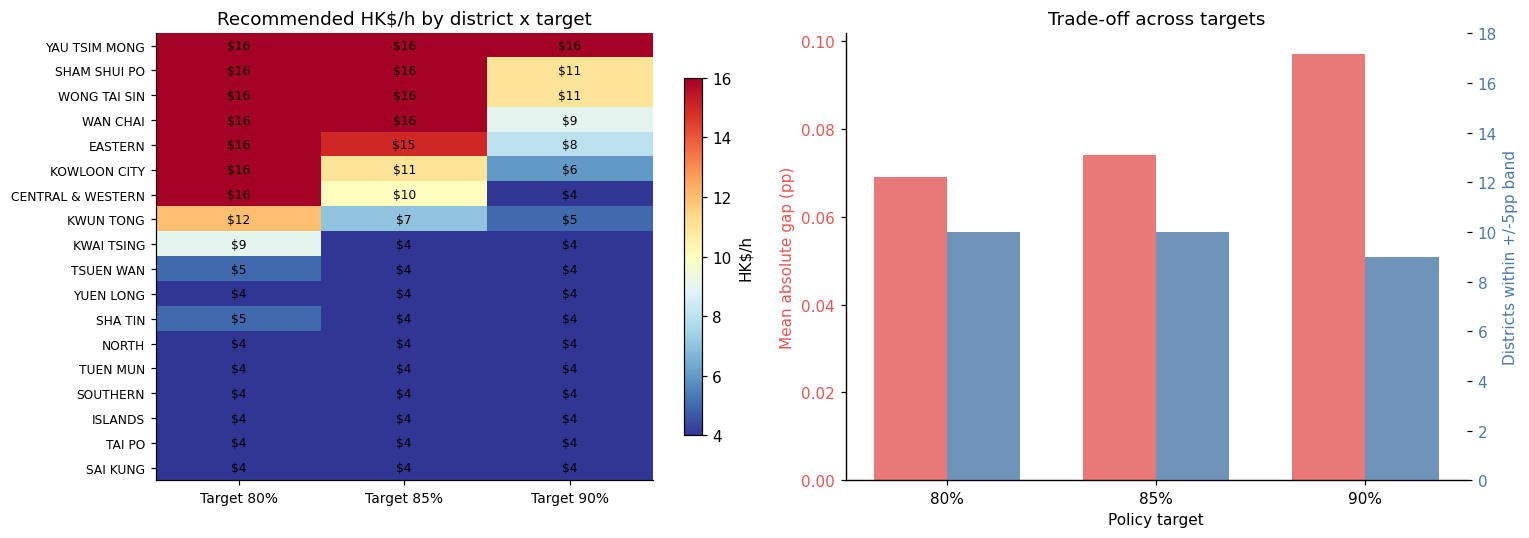

In [29]:
TARGETS = [0.80, 0.85, 0.90]

def best_tariff(baseline_arr, eta, target):
    best_p, best_occ, best_gap = None, None, np.inf
    for p in range(int(SAFE_RANGE[0]), int(SAFE_RANGE[1]) + 1):
        occ = float(np.mean(adjust_for_price(baseline_arr, p, eta)))
        gap = abs(occ - target)
        if gap < best_gap:
            best_p, best_occ, best_gap = p, occ, gap
    return best_p, best_occ, best_gap

sens_rows = []
for cluster, sub in panel.groupby('District'):
    eta_c = ELAST_BY_CLUSTER[cluster]
    baseline = sub['BaselinePred_at_$8'].values
    for tgt in TARGETS:
        p, occ, gap = best_tariff(baseline, eta_c, tgt)
        sens_rows.append({
            'District': cluster,
            'Target': tgt,
            'RecommendedPrice': p,
            'ExpectedOcc': round(occ, 4),
            'AbsGap': round(gap, 4),
            'Within_5pp': gap <= 0.05,
            'Within_2pp': gap <= 0.02,
        })
sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(f'{RESDIR}/target_sensitivity.csv', index=False)

summary = (sens_df.groupby('Target')
                  .agg(MeanGap=('AbsGap', 'mean'),
                       MeanPrice=('RecommendedPrice', 'mean'),
                       N_within_5pp=('Within_5pp', 'sum'),
                       N_within_2pp=('Within_2pp', 'sum'))
                  .round(3)
                  .reset_index())
summary.to_csv(f'{RESDIR}/target_sensitivity_summary.csv', index=False)

print('Trade-off across targets:')
print(summary.to_string(index=False))

print('\nDistricts within +/- 1pp of each target:')
for tgt in TARGETS:
    hit = sens_df[(sens_df['Target'] == tgt) & (sens_df['AbsGap'] <= 0.01)]
    names = ', '.join(hit['District'].tolist()) or '(none)'
    print(f'Target {int(tgt*100)}%: {len(hit)}/18 -> {names}')

# ============
# Figure 5
# ============
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

order = (panel.groupby('District')['DailyOccupancy'].mean().sort_values(ascending=False).index.tolist())
pivot = sens_df.pivot(index='District', columns='Target', values='RecommendedPrice').reindex(order)
pivot.columns = [f'Target {int(t*100)}%' for t in pivot.columns]

im = axs[0].imshow(pivot.values, aspect='auto', cmap='RdYlBu_r', vmin=4, vmax=16)
axs[0].set_yticks(range(len(pivot.index)))
axs[0].set_yticklabels(pivot.index, fontsize=8)
axs[0].set_xticks(range(len(pivot.columns)))
axs[0].set_xticklabels(pivot.columns, fontsize=9)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axs[0].text(j, i, f'${int(pivot.values[i, j])}', ha='center', va='center', fontsize=8, color='black')
axs[0].set_title('Recommended HK$/h by district x target')
plt.colorbar(im, ax=axs[0], label='HK$/h', shrink=0.8)

x = np.arange(len(TARGETS))
width = 0.35
axs[1].bar(x - width/2, summary['MeanGap'], width, color='#e45756', alpha=0.8, label='Mean |gap| (pp)')
ax2 = axs[1].twinx()
ax2.bar(x + width/2, summary['N_within_5pp'], width, color='#4c78a8', alpha=0.8, label='# districts within +/-5pp')
axs[1].set_xticks(x)
axs[1].set_xticklabels([f'{int(t*100)}%' for t in TARGETS])
axs[1].set_xlabel('Policy target')
axs[1].set_ylabel('Mean absolute gap (pp)', color='#e45756')
ax2.set_ylabel('Districts within +/-5pp band', color='#4c78a8')
ax2.set_ylim(0, 18)
axs[1].set_title('Trade-off across targets')
axs[1].tick_params(axis='y', labelcolor='#e45756')
ax2.tick_params(axis='y', labelcolor='#4c78a8')

plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig09_target_sensitivity.png', bbox_inches='tight')
plt.show()

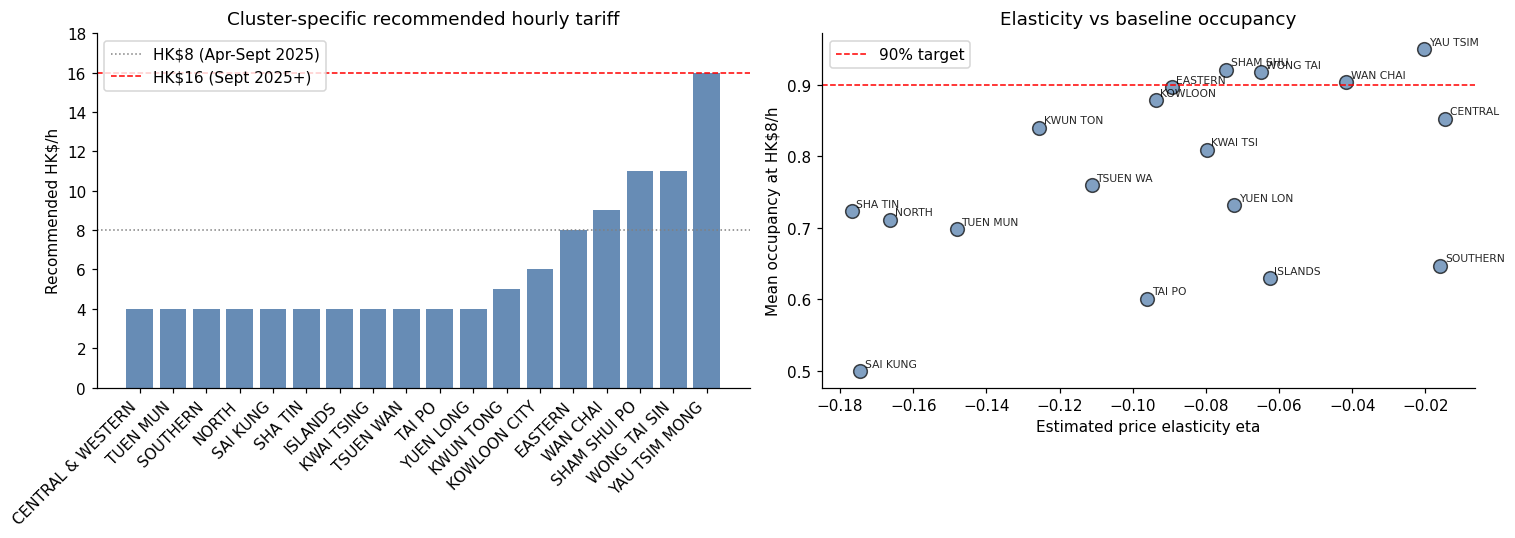

In [30]:
# ============
# Figure 3
# ============
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

plot_df = per_cluster_df.sort_values('RecommendedPrice_HKD')
axs[0].bar(plot_df['District'], plot_df['RecommendedPrice_HKD'], color='#4c78a8', alpha=0.85)
axs[0].axhline(8, color='grey', ls=':', lw=1, label='HK$8 (Apr-Sept 2025)')
axs[0].axhline(16, color='red', ls='--', lw=1, label='HK$16 (Sept 2025+)')
axs[0].set_ylabel('Recommended HK$/h')
axs[0].set_ylim(0, 18)
axs[0].set_title('Cluster-specific recommended hourly tariff')
plt.setp(axs[0].get_xticklabels(), rotation=45, ha='right')
axs[0].legend(loc='upper left')

axs[1].scatter(per_cluster_df['Eta_used'], per_cluster_df['BaselinePred_HK$8'],
               s=80, c='#4c78a8', alpha=0.7, edgecolors='black')
for _, r in per_cluster_df.iterrows():
    axs[1].annotate(r['District'][:8],
                    (r['Eta_used'], r['BaselinePred_HK$8']),
                    fontsize=7, alpha=0.85, xytext=(3, 3), textcoords='offset points')
axs[1].axhline(TARGET_OCC, color='red', ls='--', lw=1, label='90% target')
axs[1].set_xlabel('Estimated price elasticity eta')
axs[1].set_ylabel('Mean occupancy at HK$8/h')
axs[1].set_title('Elasticity vs baseline occupancy')
axs[1].legend()

plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig11_per_cluster_recommendation.png', bbox_inches='tight')
plt.show()

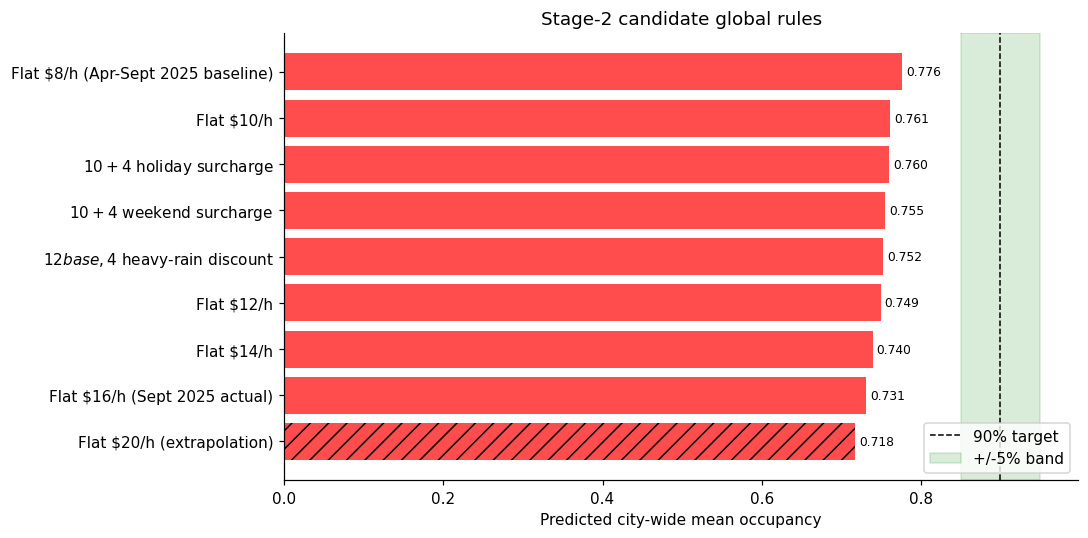

In [31]:
# ============
# Figure 4
# ============
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = global_df.sort_values('MeanOcc')

colors = ['red' if abs(v - TARGET_OCC) > 0.05 else 'green' for v in plot_df['MeanOcc']]
hatches = ['//' if e == 'YES' else '' for e in plot_df['Extrapolating']]

bars = ax.barh(plot_df['Rule'], plot_df['MeanOcc'], color=colors, alpha=0.7)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)

ax.axvline(TARGET_OCC, color='black', ls='--', lw=1.0, label='90% target')
ax.axvspan(TARGET_OCC - 0.05, TARGET_OCC + 0.05, color='green', alpha=0.15, label='+/-5% band')
ax.set_xlabel('Predicted city-wide mean occupancy')
ax.set_title('Stage-2 candidate global rules')
for i, v in enumerate(plot_df['MeanOcc']):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig10_pricing_rule_comparison.png', bbox_inches='tight')
plt.show()

In [32]:
X_at_8 = X.copy()
X_at_8['PostPriceChange'] = 0
X_at_16 = X.copy()
X_at_16['PostPriceChange'] = 1

rf = fitted['Random Forest']
panel['_rf_at_8'] = rf.predict(X_at_8)
panel['_rf_at_16'] = rf.predict(X_at_16)

tree_eta_rows = []
for c, sub in panel.groupby('District'):
    p8, p16 = sub['_rf_at_8'].mean(), sub['_rf_at_16'].mean()
    if p8 > 0 and p16 > 0:
        tree_eta = (np.log(p16) - np.log(p8)) / np.log(2)
    else:
        tree_eta = np.nan
    tree_eta_rows.append({
        'District': c,
        'RF_pred_at_$8': round(p8, 4),
        'RF_pred_at_$16': round(p16, 4),
        'Implied_eta_RF': round(tree_eta, 4),
        'Eta_we_use': round(ELAST_BY_CLUSTER[c], 4),
    })
tree_df = pd.DataFrame(tree_eta_rows).sort_values('Implied_eta_RF')
tree_df.to_csv(f'{RESDIR}/tree_vs_formula_diagnostic.csv', index=False)

print('Tree-implicit elasticity vs regression eta:')
print(tree_df.to_string(index=False))

panel.drop(columns=['_rf_at_8', '_rf_at_16'], inplace=True)

Tree-implicit elasticity vs regression eta:
         District  RF_pred_at_$8  RF_pred_at_$16  Implied_eta_RF  Eta_we_use
         SAI KUNG         0.4991          0.4398         -0.1825     -0.1745
          SHA TIN         0.7230          0.6386         -0.1792     -0.1768
            NORTH         0.7110          0.6339         -0.1656     -0.1663
         TUEN MUN         0.6981          0.6287         -0.1510     -0.1481
        KWUN TONG         0.8401          0.7698         -0.1262     -0.1255
        TSUEN WAN         0.7596          0.7054         -0.1069     -0.1112
           TAI PO         0.6007          0.5617         -0.0968     -0.0961
     KOWLOON CITY         0.8786          0.8246         -0.0916     -0.0937
          EASTERN         0.8968          0.8441         -0.0874     -0.0894
       KWAI TSING         0.8094          0.7668         -0.0779     -0.0798
     SHAM SHUI PO         0.9213          0.8758         -0.0732     -0.0745
        YUEN LONG         0.7318

In [33]:
def recommend_within_support(baseline, eta):
    rec = [{'p': p, 'gap': abs(np.mean(adjust_for_price(baseline, p, eta)) - TARGET_OCC)}
           for p in range(int(SAFE_RANGE[0]), int(SAFE_RANGE[1]) + 1)]
    return min(rec, key=lambda x: x['gap'])['p']

stability_rows = []
for cluster, sub in panel.groupby('District'):
    eta_c = ELAST_BY_CLUSTER[cluster]
    baseline = sub['BaselinePred_at_$8'].values
    p_base = recommend_within_support(baseline, eta_c)

    # eta - 0.05 always remains negative (demand-law-valid)
    p_low = recommend_within_support(baseline, eta_c - 0.05)

    # eta + 0.05: if it would cross zero, perturbation is degenerate;
    # demand-law clamp forces predicted occ identical at all prices,
    # so the recommendation cannot move from baseline.
    if eta_c + 0.05 >= 0:
        p_high = p_base                       # degenerate: report no-op
        degenerate = True
    else:
        p_high = recommend_within_support(baseline, eta_c + 0.05)
        degenerate = False

    stability_rows.append({
        'District': cluster,
        'P_base': p_base,
        'P_eta_minus': p_low,
        'P_eta_plus': p_high,
        'Range': max(p_low, p_high, p_base) - min(p_low, p_high, p_base),
        'Degenerate_eta_plus': degenerate,    # for transparency
    })

stab_df = pd.DataFrame(stability_rows).sort_values('Range', ascending=False)
stab_df.to_csv(f'{RESDIR}/pricing_sensitivity.csv', index=False)
print('Recommendation stability under +/- 0.05 eta:')
print(stab_df.to_string(index=False))
n_same = (stab_df['Range'] == 0).sum()
print(f'\n{n_same} of {len(stab_df)} districts get an identical recommendation.')

Recommendation stability under +/- 0.05 eta:
         District  P_base  P_eta_minus  P_eta_plus  Range  Degenerate_eta_plus
     WONG TAI SIN      11            9          16      7                False
     SHAM SHUI PO      11           10          16      6                False
     KOWLOON CITY       6            7           5      2                False
          EASTERN       8            8           7      1                False
         WAN CHAI       9            8           9      1                 True
        KWUN TONG       5            5           4      1                False
CENTRAL & WESTERN       4            4           4      0                 True
            NORTH       4            4           4      0                False
       KWAI TSING       4            4           4      0                False
          ISLANDS       4            4           4      0                False
          SHA TIN       4            4           4      0                False
       